# 06 · Khối Transformer – LayerNorm, residual, feed-forward, dropout

**Vị trí trong luồng dữ liệu:** văn bản → token → embedding (+ vị trí) → **N khối Transformer** → logits → token tiếp theo

Attention cho các token trao đổi thông tin. Để xếp chồng được nhiều lớp và học ổn định, mỗi khối Transformer còn cần
thêm vài thành phần. Đây là khối **pre-norm** mà MiniGPT dùng (giống GPT-2):

```
x ──┬──► LayerNorm ─► Multi-head attention ─► Dropout ──► (+) ──┬──► LayerNorm ─► Feed-forward ─► Dropout ──► (+) ──► ra
    │                                                     ▲     │                                                ▲
    └────────────────────── residual ─────────────────────┘     └──────────────────── residual ──────────────────┘
```

Trong code (`src/vietformer/block.py`), cả khối chỉ là hai dòng:

```python
x = x + self.attn(self.ln1(x))   # các token trao đổi thông tin
x = x + self.ffn(self.ln2(x))    # từng token tự xử lý thông tin vừa nhận
```

Notebook này đi qua từng thành phần và giải thích vai trò của nó.

⏱ Thời gian chạy: khoảng 10 giây.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "vietformer").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import torch
from torch import nn

from vietformer import viz
from vietformer.block import FeedForward, LayerNorm, TransformerBlock
from vietformer.utils import set_seed

viz.set_style()
set_seed(0)
torch.set_printoptions(precision=3, sci_mode=False)

## 1. LayerNorm: giữ các con số ở thang đo ổn định

Qua nhiều lớp, giá trị trong vector có thể phình to hoặc teo nhỏ dần, làm việc học mất ổn định. **LayerNorm** chuẩn
hóa vector của **từng token** về trung bình 0, độ lệch chuẩn 1, rồi co giãn lại bằng hai tham số học được `γ` (weight)
và `β` (bias):

$$\text{LayerNorm}(x) = \gamma \cdot \frac{x - \text{mean}(x)}{\sqrt{\text{var}(x) + \epsilon}} + \beta$$

Chuẩn hóa theo chiều cuối (`d_model`), tức là mỗi token độc lập với các token khác và với các chuỗi khác trong batch.

In [2]:
x = torch.tensor([[1.0, 2.0, 3.0, 4.0],          # token có giá trị nhỏ, tăng đều
                  [100.0, 200.0, 300.0, 400.0],  # lớn gấp 100 lần nhưng cùng "hình dạng" tăng đều
                  [3.0, -1.0, 0.0, 10.0]])       # hình dạng khác
ln = LayerNorm(4)
y = ln(x)
print("trước:\n", x, "\nsau LayerNorm:\n", y.detach())
print("\ntrung bình mỗi hàng:", y.mean(dim=-1).detach())
print("độ lệch chuẩn mỗi hàng:", y.std(dim=-1, unbiased=False).detach())
print("\nGiống nn.LayerNorm của PyTorch?", torch.allclose(y, nn.LayerNorm(4)(x), atol=1e-5))

trước:
 tensor([[  1.,   2.,   3.,   4.],
        [100., 200., 300., 400.],
        [  3.,  -1.,   0.,  10.]]) 
sau LayerNorm:
 tensor([[-1.342, -0.447,  0.447,  1.342],
        [-1.342, -0.447,  0.447,  1.342],
        [ 0.000, -0.930, -0.697,  1.627]])

trung bình mỗi hàng: tensor([0.000, 0.000, 0.000])
độ lệch chuẩn mỗi hàng: tensor([1.000, 1.000, 1.000])

Giống nn.LayerNorm của PyTorch? True


Hai hàng đầu khác nhau 100 lần về độ lớn nhưng có cùng "hình dạng" (tăng đều), nên sau LayerNorm chúng giống hệt
nhau; hàng thứ ba có hình dạng khác nên cho kết quả khác. LayerNorm giữ lại *hình dạng tương đối* của vector và bỏ đi
*thang đo*.

## 2. Residual connection: đường tắt cho gradient

Thay vì `x = f(x)`, khối Transformer tính `x = x + f(x)`. Hai lợi ích:

* Mỗi khối chỉ cần học **phần bổ sung** cho `x`; nếu khối chưa hữu ích, nó có thể để `f(x) ≈ 0` mà không phá hỏng thông tin.
* Khi lan truyền ngược, đạo hàm của `x + f(x)` theo `x` là `1 + f'(x)`: luôn có một đường "1" đưa gradient thẳng về các
  lớp đầu, nên mạng rất sâu vẫn học được.

Thí nghiệm: chồng 32 khối, một lần **có** residual và một lần **bỏ** residual, rồi đo độ lớn gradient mà lớp
feed-forward của từng khối nhận được.

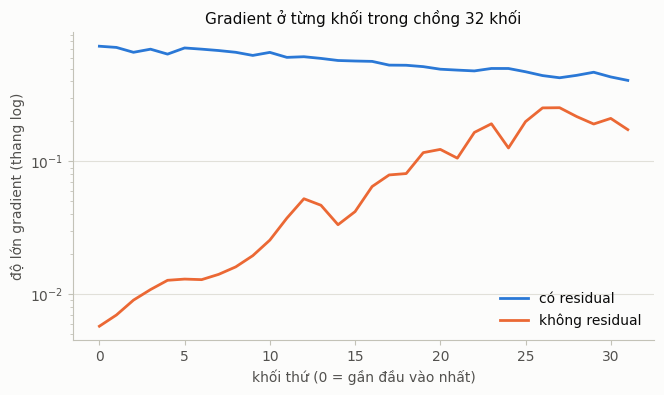

In [3]:
class BlockWithoutResidual(TransformerBlock):
    """Giống TransformerBlock nhưng bỏ residual: x = f(x) thay vì x = x + f(x)."""

    def forward(self, x):
        x = self.attn(self.ln1(x))
        return self.ffn(self.ln2(x))


gradient_norms = {}
for name, block_class in [("có residual", TransformerBlock), ("không residual", BlockWithoutResidual)]:
    set_seed(0)
    stack = nn.Sequential(*[block_class(d_model=64, n_head=4, block_size=32) for _ in range(32)])
    out = stack(torch.randn(4, 16, 64))
    out.pow(2).mean().backward()
    gradient_norms[name] = [block.ffn.net[0].weight.grad.norm().item() for block in stack]

fig, ax = plt.subplots(figsize=(7.5, 4))
for color, (name, norms) in zip(viz.COLORS, gradient_norms.items()):
    ax.plot(range(32), norms, color=color, label=name)
ax.set_yscale("log")
ax.set(xlabel="khối thứ (0 = gần đầu vào nhất)", ylabel="độ lớn gradient (thang log)",
       title="Gradient ở từng khối trong chồng 32 khối")
ax.grid(axis="y")
ax.legend()
plt.show()

Có residual, gradient gần như đều nhau ở mọi khối. Không có residual, các khối gần đầu vào nhận gradient nhỏ hơn
khoảng 100 lần – chúng gần như không học được gì (hiện tượng **gradient biến mất**, vanishing gradient).

## 3. Feed-forward với GELU

Sau khi attention gom thông tin từ các token khác, **feed-forward** xử lý vector của *từng token một cách độc lập*:
phóng to 4 lần, qua một hàm phi tuyến, rồi thu nhỏ lại. Có thể coi attention là "giao tiếp", còn feed-forward là
"suy nghĩ". Phần lớn tham số của mô hình nằm ở đây.

Hàm phi tuyến là **GELU**: giống ReLU nhưng mượt, cho qua một chút giá trị âm gần 0 thay vì cắt cụt.

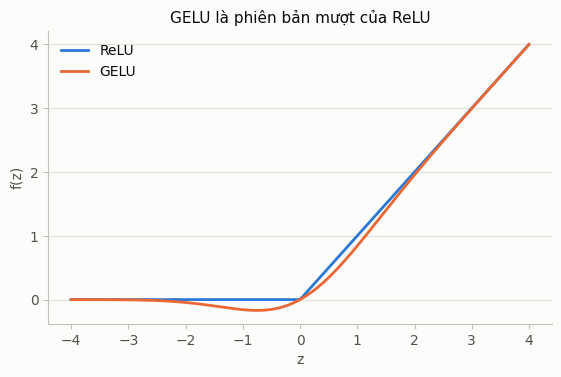

vào: (2, 5, 128) → lớp ẩn: (2, 5, 512) → ra: (2, 5, 128)
số tham số feed-forward: 131712


In [4]:
z = torch.linspace(-4, 4, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(z, torch.relu(z), color=viz.COLORS[0], label="ReLU")
ax.plot(z, nn.functional.gelu(z), color=viz.COLORS[1], label="GELU")
ax.set(xlabel="z", ylabel="f(z)", title="GELU là phiên bản mượt của ReLU")
ax.grid(axis="y")
ax.legend()
plt.show()

ffn = FeedForward(d_model=128)
x = torch.randn(2, 5, 128)
hidden = ffn.net[0](x)
print("vào:", tuple(x.shape), "→ lớp ẩn:", tuple(hidden.shape), "→ ra:", tuple(ffn(x).shape))
print("số tham số feed-forward:", sum(p.numel() for p in ffn.parameters()))

## 4. Dropout: chống học thuộc lòng

Khi huấn luyện, `Dropout(p)` ngẫu nhiên đặt một tỉ lệ `p` các giá trị về 0 và nhân phần còn lại với `1 / (1 − p)`
để giữ nguyên giá trị trung bình. Mô hình buộc phải học các đặc trưng "dự phòng" thay vì dựa vào vài neuron cụ thể,
nhờ đó bớt **overfitting**. Khi đánh giá hoặc sinh văn bản (`model.eval()`), dropout bị tắt.

In [5]:
dropout = nn.Dropout(p=0.5)
ones = torch.ones(10)
dropout.train()
print("chế độ train:", dropout(ones))
dropout.eval()
print("chế độ eval :", dropout(ones))

chế độ train: tensor([2., 0., 2., 2., 0., 0., 2., 0., 0., 2.])
chế độ eval : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


MiniGPT đặt dropout ở ba chỗ: sau khi cộng embedding + vị trí, trên trọng số attention, và ở cuối mỗi nhánh
(attention, feed-forward) trước khi cộng residual.

## 5. Pre-norm hay post-norm?

Bài báo gốc (2017) dùng **post-norm**: `x = LayerNorm(x + f(x))`. GPT-2 trở đi chuyển sang **pre-norm**:
`x = x + f(LayerNorm(x))`. Với pre-norm, đường residual từ đầu vào tới đầu ra không đi qua phép chuẩn hóa nào, nên
gradient chảy thẳng và mô hình sâu học ổn định hơn, ít phụ thuộc vào "warmup" learning rate. Vì đường residual không
được chuẩn hóa, pre-norm cần thêm một LayerNorm cuối cùng (`ln_f` trong `MiniGPT`) trước lớp đầu ra.

## 6. Ghép lại: TransformerBlock

In [6]:
block = TransformerBlock(d_model=128, n_head=4, block_size=64, dropout=0.1)
x = torch.randn(2, 10, 128)
print("vào:", tuple(x.shape), "→ ra:", tuple(block(x).shape), "(shape không đổi nên xếp chồng được bao nhiêu khối cũng được)\n")

parts = {"ln1": block.ln1, "attn (Q, K, V, proj)": block.attn, "ln2": block.ln2, "ffn": block.ffn}
total = sum(p.numel() for p in block.parameters())
for name, module in parts.items():
    n = sum(p.numel() for p in module.parameters())
    print(f"{name:22} {n:>8,} tham số ({n / total:5.1%})")
print(f"{'tổng':22} {total:>8,}")

vào: (2, 10, 128) → ra: (2, 10, 128) (shape không đổi nên xếp chồng được bao nhiêu khối cũng được)

ln1                         256 tham số ( 0.1%)
attn (Q, K, V, proj)     65,664 tham số (33.2%)
ln2                         256 tham số ( 0.1%)
ffn                     131,712 tham số (66.6%)
tổng                    197,888


Với `d = 128`: attention có `4·d² + d` tham số (Q, K, V, proj và bias của proj), feed-forward có `8·d² + 5·d`
(hai ma trận `d × 4d` và bias). Feed-forward chiếm khoảng 2/3 tham số của khối.

Xếp chồng 4 khối – đúng như MiniGPT – và kiểm tra rằng tính nhân quả vẫn được giữ qua nhiều lớp:

In [7]:
set_seed(0)
stack = nn.Sequential(*[TransformerBlock(128, 4, 64) for _ in range(4)]).eval()
x = torch.randn(1, 12, 128)
x_changed = x.clone()
x_changed[0, 8:] = torch.randn(4, 128)  # đổi các token từ vị trí 8 trở đi
with torch.no_grad():
    same = torch.allclose(stack(x)[0, :8], stack(x_changed)[0, :8], atol=1e-5)
print("Đổi token tương lai không ảnh hưởng 8 vị trí đầu qua 4 khối?", same)

Đổi token tương lai không ảnh hưởng 8 vị trí đầu qua 4 khối? True


## Tóm tắt

| Thành phần | Vai trò |
|---|---|
| LayerNorm | đưa vector mỗi token về thang đo ổn định (trung bình 0, độ lệch chuẩn 1) |
| Multi-head attention | các token trao đổi thông tin ("giao tiếp") |
| Residual | đường tắt cho gradient; mỗi khối chỉ học phần bổ sung |
| Feed-forward + GELU | xử lý riêng từng token ("suy nghĩ"), chiếm phần lớn tham số |
| Dropout | chống overfitting khi huấn luyện; tắt khi đánh giá |

**Tiếp theo:** notebook 07 ghép embedding + N khối + lớp đầu ra thành MiniGPT và huấn luyện trên Truyện Kiều.

---

## Bài tập

Đáp án: `solutions/06_transformer_block.md`

**Bài 1.** Viết lớp `PostNormBlock` (kế thừa `TransformerBlock`) theo kiểu bài báo gốc:
`x = ln1(x + attn(x))`, rồi `x = ln2(x + ffn(x))`. Kiểm tra shape đầu ra và chạy lại thí nghiệm gradient ở mục 2 với
lớp mới. Bạn thấy gì?

In [8]:
class PostNormBlock(TransformerBlock):
    def forward(self, x):
        # TODO: cài đặt post-norm
        return x


print(PostNormBlock(64, 4, 32)(torch.randn(2, 5, 64)).shape)

torch.Size([2, 5, 64])


**Bài 2.** Vì sao feed-forward phóng to 4 lần rồi thu nhỏ lại, thay vì giữ nguyên `d_model`? Hãy thử đếm tham số và
suy nghĩ về "dung lượng" của lớp ẩn.

**Bài 3.** Tính bằng công thức số tham số của một `TransformerBlock` với `d_model = 256` (gợi ý: LayerNorm có `2·d`
tham số), rồi kiểm tra bằng code.

In [9]:
# TODO: so sánh công thức của bạn với sum(p.numel() for p in TransformerBlock(256, 4, 64).parameters())